
### FINAL-01. Environment and Frozen Model Configuration

**Objective:** Initialize the final evaluation environment and retrieve the model and decision threshold selected in RQ2 and RQ3.

**Input:** RQ2 selected_strategy.json, RQ3 selected_threshold.json, and the saved XGBoost model.

**Procedure:** Mount Google Drive, validate the selected model and threshold metadata, establish the Final Evaluation directories, and freeze the configuration before loading the held-out Test dataset.

**Output:** Verified model artifact, decision threshold, and evaluation paths.

**Methodological consideration:** The Test partition is reserved exclusively for final performance estimation. No model retraining, threshold optimization, or configuration selection is permitted using Test outcomes.


In [ ]:

# ============================================================
# FINAL-01 — ENVIRONMENT AND FROZEN CONFIGURATION
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Kết nối Google Drive.
drive.mount("/content/drive")

# 2. Giữ nguyên hệ thống thư mục của nhóm.
ROOT = Path(
    "/content/drive/Shareddrives/"
    "M(anchine) L(earning)/Output"
)

EXP = ROOT / "ML_Experiments"

PP_DIR = ROOT / "Preprocessing"
RQ2_DIR = EXP / "RQ2"
RQ3_DIR = EXP / "RQ3"
FINAL_DIR = EXP / "Final"

FINAL_RESULT_DIR = FINAL_DIR / "results"
FINAL_FIGURE_DIR = FINAL_RESULT_DIR / "figures"

# 3. Đọc các file cấu hình đã chốt.
rq2_config_path = (
    RQ2_DIR / "results" / "selected_strategy.json"
)

rq3_config_path = (
    RQ3_DIR / "results" / "selected_threshold.json"
)

assert rq2_config_path.is_file(), (
    f"Missing RQ2 selection: {rq2_config_path}"
)

assert rq3_config_path.is_file(), (
    "RQ3-08 chưa lưu selected_threshold.json. "
    "Hãy hoàn thành RQ3 trước khi mở Test."
)

with open(rq2_config_path, "r", encoding="utf-8") as f:
    rq2_config = json.load(f)

with open(rq3_config_path, "r", encoding="utf-8") as f:
    rq3_config = json.load(f)

# 4. Kiểm tra thống nhất lựa chọn RQ1–RQ3.
assert rq2_config["selected_algorithm"] == "XGBoost"
assert rq2_config["selected_strategy"] == "Class_Weight"

assert rq3_config["research_question"] == "RQ3"

assert rq3_config["selected_algorithm"] == "XGBoost"
assert (
    rq3_config["selected_imbalance_strategy"]
    == "Class_Weight"
)

assert rq3_config["selection_dataset"] == "Validation_20pct"
assert rq3_config["selection_metric"] == "F1"

assert rq3_config["test_used_for_selection"] is False
assert rq2_config["test_used_for_selection"] is False

# 5. Lấy đúng threshold đã lưu.
FINAL_THRESHOLD = float(
    rq3_config["selected_threshold"]
)

assert np.isfinite(FINAL_THRESHOLD)
assert 0 <= FINAL_THRESHOLD <= 1

# 6. Kiểm tra model của RQ2 và RQ3 là cùng file.
MODEL_PATH = Path(rq3_config["model_path"])

assert MODEL_PATH == Path(
    rq2_config["selected_model_path"]
)

assert MODEL_PATH.is_file()

# 7. Đường dẫn Test được xác định trước.
TEST_PATH = (
    PP_DIR / "3.2.7_Tree_Test_20pct.parquet"
)

assert TEST_PATH.is_file(), (
    f"Missing Test dataset: {TEST_PATH}"
)

# 8. Xác nhận thư mục kết quả.
assert FINAL_RESULT_DIR.is_dir(), (
    f"Missing Final results directory: {FINAL_RESULT_DIR}"
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 60)
print("FINAL MODEL EVALUATION — CONFIGURATION CHECK")
print("=" * 60)

print("Algorithm: XGBoost")
print("Strategy: Class_Weight")
print("Selected Threshold:", FINAL_THRESHOLD)

print("Model:", MODEL_PATH.name)
print("Test Dataset:", TEST_PATH.name)

print("\nPASS: Final evaluation configuration frozen.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FINAL MODEL EVALUATION — CONFIGURATION CHECK
Algorithm: XGBoost
Strategy: Class_Weight
Selected Threshold: 0.9941363334655762
Model: Class_Weight.joblib
Test Dataset: 3.2.7_Tree_Test_20pct.parquet

PASS: Final evaluation configuration frozen.



### FINAL-02. Held-Out Test Prediction

**Objective:** Generate fraud scores and binary classification decisions on the independent Test partition using the frozen model and threshold.

**Input:** Saved XGBoost with Class Weight model, preprocessed Tree Test dataset, and selected threshold from RQ3.

**Procedure:** Load the trained model without fitting, verify the feature schema, generate fraud scores using predict_proba, and apply the selected decision threshold.

**Output:** Final Test predictions containing ground-truth labels, fraud scores, predicted labels, and the applied threshold.

**Methodological consideration:** Ground-truth labels are excluded from model inputs and used only for evaluation. The model and selected threshold remain unchanged.


In [ ]:

# ============================================================
# FINAL-02 — GENERATE HELD-OUT TEST PREDICTIONS
# ============================================================

# 1. Load mô hình đã huấn luyện và được chọn từ RQ2.
final_model = joblib.load(MODEL_PATH)

# 2. Đọc Test đã được transform bằng Tree Preprocessor.
test_df = pd.read_parquet(TEST_PATH)

TARGET = "isFraud"

assert TARGET in test_df.columns
assert test_df.index.is_unique

# 3. Tách nhãn và các features.
y_test = test_df[TARGET].astype(np.int8)

X_test = test_df.drop(columns=[TARGET])

# Kiểm tra không đưa nhãn vào model.
assert TARGET not in X_test.columns

assert len(X_test) == 1_272_524
assert int(y_test.sum()) == 1_642
assert X_test.shape[1] == 13

# 4. Kiểm tra feature schema theo mô hình đã lưu.
assert hasattr(final_model, "predict_proba")
assert hasattr(final_model, "classes_")

assert set(final_model.classes_) == {0, 1}

assert (
    X_test.shape[1] == final_model.n_features_in_
), "Test feature count does not match the model."

# Kiểm tra đúng tên và thứ tự features khi có metadata.
if hasattr(final_model, "feature_names_in_"):
    assert list(X_test.columns) == list(
        final_model.feature_names_in_
    ), "Test feature names/order do not match the model."

# 5. Chỉ lấy score của class fraud = 1.
fraud_class_position = list(
    final_model.classes_
).index(1)

test_scores = final_model.predict_proba(
    X_test
)[:, fraud_class_position]

# 6. Kiểm tra scores.
assert len(test_scores) == len(y_test)
assert np.isfinite(test_scores).all()
assert ((test_scores >= 0) & (test_scores <= 1)).all()

# 7. Áp dụng threshold đã chốt từ RQ3.
test_predictions = (
    test_scores >= FINAL_THRESHOLD
).astype(np.int8)

# 8. Lưu dự đoán, giữ nguyên transaction index.
test_predictions_df = pd.DataFrame(
    {
        "isFraud": y_test.to_numpy(),
        "fraud_score": test_scores,
        "predicted_label": test_predictions,
        "threshold_used": FINAL_THRESHOLD
    },
    index=test_df.index
)

predictions_path = (
    FINAL_RESULT_DIR / "final_test_predictions.parquet"
)

test_predictions_df.to_parquet(
    predictions_path,
    index=True
)

print("=" * 60)
print("FINAL-02 — TEST PREDICTIONS")
print("=" * 60)

print("Test records:", len(test_df))
print("Actual fraud:", int(y_test.sum()))
print("Test features:", X_test.shape[1])
print("Selected threshold:", FINAL_THRESHOLD)

print("Flagged transactions:", int(test_predictions.sum()))

print("\nSaved:", predictions_path)
print("\nPASS: Final Test predictions generated.")


FINAL-02 — TEST PREDICTIONS
Test records: 1272524
Actual fraud: 1642
Test features: 13
Selected threshold: 0.9941363334655762
Flagged transactions: 1640

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/Final/results/final_test_predictions.parquet

PASS: Final Test predictions generated.



### FINAL-03. Final Test Performance Evaluation

**Objective:** Evaluate the generalization performance of the selected fraud detection model on the independent Test partition.

**Input:** Held-out Test labels, fraud scores, binary predictions, and the selected threshold.

**Procedure:** Calculate threshold-independent ranking metrics and threshold-dependent classification metrics, construct the confusion matrix, and save final evaluation results.

**Output:** final_test_metrics.json, final_test_metrics.csv, and final_test_confusion_matrix.png.

**Methodological consideration:** Test metrics are reported without reselecting the model, class imbalance strategy, or decision threshold. Any performance differences from Validation are interpreted as evaluation outcomes rather than triggers for additional optimization on Test.


,Dataset,Algorithm,Imbalance_Strategy,Threshold,Test_Records,Actual_Fraud,AP,ROC_AUC,Accuracy,Precision,Recall,F1,TP,FP,FN,TN,Alerts,Alert_Rate
0,Test_20pct,XGBoost,Class_Weight,0.994136,1272524,1642,0.99912,0.999894,0.999998,1.0,0.998782,0.999391,1640,0,2,1270882,1640,0.001289


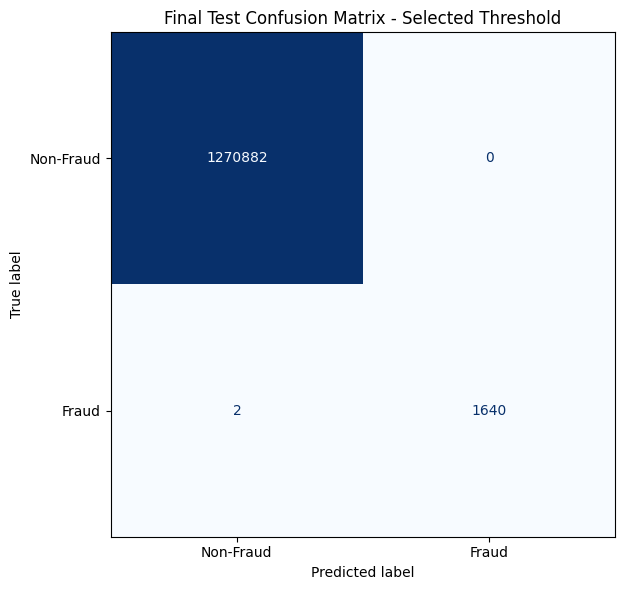

FINAL TEST EVALUATION COMPLETED
AP: 0.99912
ROC-AUC: 0.999894
Precision: 1.0
Recall: 0.998782
F1: 0.999391

TP: 1640
FP: 0
FN: 2
TN: 1270882

PASS: Final Test metrics saved.


In [ ]:

# ============================================================
# FINAL-03 — FINAL TEST PERFORMANCE EVALUATION
# ============================================================

# 1. Tính confusion matrix.
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# 2. Tính các metrics.
final_metrics = {
    "Dataset": "Test_20pct",
    "Algorithm": "XGBoost",
    "Imbalance_Strategy": "Class_Weight",
    "Threshold": float(FINAL_THRESHOLD),

    "Test_Records": int(len(y_test)),
    "Actual_Fraud": int(y_test.sum()),

    "AP": float(
        average_precision_score(y_test, test_scores)
    ),
    "ROC_AUC": float(
        roc_auc_score(y_test, test_scores)
    ),
    "Accuracy": float(
        accuracy_score(y_test, test_predictions)
    ),
    "Precision": float(
        precision_score(
            y_test, test_predictions, zero_division=0
        )
    ),
    "Recall": float(
        recall_score(
            y_test, test_predictions, zero_division=0
        )
    ),
    "F1": float(
        f1_score(
            y_test, test_predictions, zero_division=0
        )
    ),

    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn),

    "Alerts": int(tp + fp),
    "Alert_Rate": float(
        (tp + fp) / len(y_test)
    )
}

# 3. Kiểm tra tính nhất quán.
assert (
    tp + fp + fn + tn == len(y_test)
)

assert (
    tp + fn == int(y_test.sum())
)

assert (
    tp + fp == int(test_predictions.sum())
)

# 4. Lưu kết quả.
metrics_json_path = (
    FINAL_RESULT_DIR / "final_test_metrics.json"
)

metrics_csv_path = (
    FINAL_RESULT_DIR / "final_test_metrics.csv"
)

with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(
        final_metrics,
        f,
        indent=2,
        ensure_ascii=False
    )

pd.DataFrame([final_metrics]).to_csv(
    metrics_csv_path,
    index=False
)

# 5. Hiển thị metrics.
display(
    pd.DataFrame([final_metrics]).round(6)
)

# 6. Vẽ confusion matrix.
cm = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Fraud", "Fraud"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Final Test Confusion Matrix - Selected Threshold"
)

plt.tight_layout()

cm_path = (
    FINAL_FIGURE_DIR / "final_test_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 60)
print("FINAL TEST EVALUATION COMPLETED")
print("=" * 60)

print("AP:", round(final_metrics["AP"], 6))
print("ROC-AUC:", round(final_metrics["ROC_AUC"], 6))
print("Precision:", round(final_metrics["Precision"], 6))
print("Recall:", round(final_metrics["Recall"], 6))
print("F1:", round(final_metrics["F1"], 6))

print("\nTP:", final_metrics["TP"])
print("FP:", final_metrics["FP"])
print("FN:", final_metrics["FN"])
print("TN:", final_metrics["TN"])

print("\nPASS: Final Test metrics saved.")



### FINAL-04. Validation–Test Performance Comparison and Final Audit

**Objective:** Assess the consistency of the selected fraud detection model's performance between the Validation and held-out Test datasets, and verify the integrity of the final evaluation artifacts.

**Input:**
- RQ3 `selected_threshold.json`.
- Final `final_test_metrics.json`.
- Final `final_test_predictions.parquet`.
- RQ3 `rq3_threshold_comparison.csv`.

**Procedure:**
1. Retrieve the frozen XGBoost with Class Weight configuration and selected decision threshold.
2. Verify that the Validation and Test results correspond to the same model and threshold.
3. Compare Precision, Recall, F1-score, Average Precision (AP), ROC-AUC, and confusion matrix outcomes.
4. Independently check the consistency of saved Test predictions and reported metrics.
5. Generate comparison tables and visualizations for research reporting.

**Output:**
- `final_validation_test_comparison.csv`
- `final_validation_test_metric_differences.csv`
- `final_evaluation_audit.json`
- `final_validation_test_metrics.png`
- `final_validation_test_errors.png`

**Methodological consideration:** The selected model and threshold remain unchanged. The Test dataset is used exclusively to evaluate the previously selected configuration. Differences between Validation and Test performance are descriptive evidence of observed generalization and must not be interpreted as proof of deployment stability or used for further optimization.

**Research scope:** Post-Transaction Fraud Detection and Review Support System using the PaySim simulated transaction dataset.


PASS: All FINAL-04 input files are available.

FROZEN CONFIGURATION
Algorithm: XGBoost
Imbalance Strategy: Class_Weight
Selected Threshold: 0.9941363334655762

PASS: Validation results match RQ3 artifacts.
PASS: Saved Test predictions and metrics verified.

VALIDATION VS TEST PERFORMANCE


,Metric,Validation,Test,Difference_Test_Minus_Validation
0,AP,9.981960e-01,9.991200e-01,0.000923
1,ROC_AUC,9.998450e-01,9.998940e-01,0.000050
2,Precision,1.000000e+00,1.000000e+00,0.000000
3,Recall,9.957400e-01,9.987820e-01,0.003042
4,F1,9.978650e-01,9.993910e-01,0.001525
5,TP,1.636000e+03,1.640000e+03,4.000000
6,FP,0.000000e+00,0.000000e+00,0.000000
7,FN,7.000000e+00,2.000000e+00,-5.000000
8,TN,1.270881e+06,1.270882e+06,1.000000
9,Alerts,1.636000e+03,1.640000e+03,4.000000



METRIC DIFFERENCES


,Metric,Validation,Test,Difference_Test_Minus_Validation,Difference_Percentage_Points
0,AP,0.998196,0.999120,0.000923,0.092343
1,ROC_AUC,0.999845,0.999894,0.000050,0.004973
2,Precision,1.000000,1.000000,0.000000,0.000000
3,Recall,0.995740,0.998782,0.003042,0.304247
4,F1,0.997865,0.999391,0.001525,0.152541
10,Alert_Rate,0.001286,0.001289,0.000003,0.000314


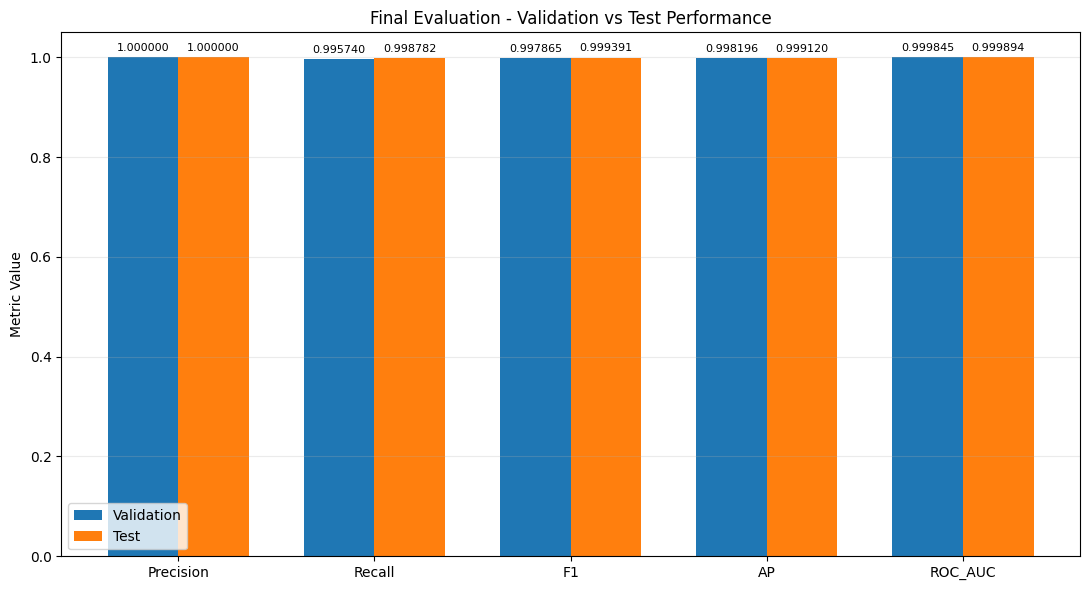

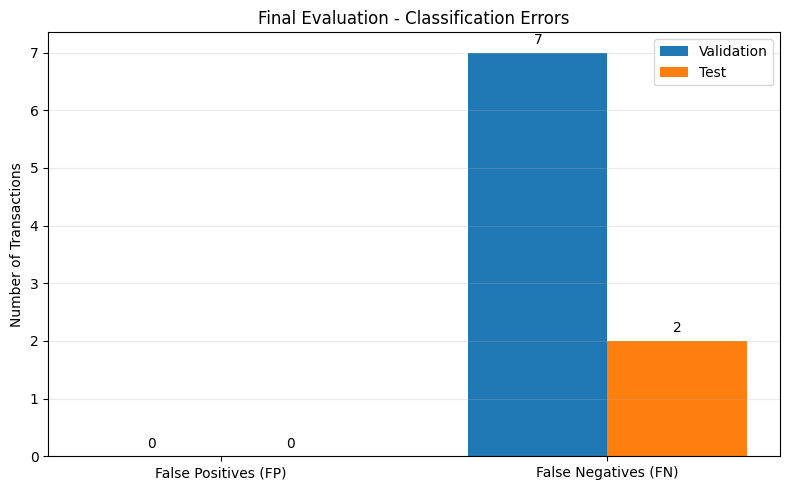


FINAL-04 — VALIDATION–TEST COMPARISON COMPLETED
Model: XGBoost + Class Weight
Selected threshold: 0.9941363334655762

VALIDATION
F1: 0.997865
FP: 0
FN: 7

FINAL TEST
F1: 0.999391
FP: 0
FN: 2

Saved outputs:
- final_validation_test_comparison.csv
- final_validation_test_metric_differences.csv
- final_validation_test_metrics.png
- final_validation_test_errors.png
- final_evaluation_audit.json

PASS: FINAL-04 completed successfully.
Model and threshold remain unchanged.


In [ ]:

# ============================================================
# FINAL-04 — VALIDATION VS TEST COMPARISON AND FINAL AUDIT
# ============================================================

# ------------------------------------------------------------
# STEP 1. IMPORT AND INPUT PATHS
# ------------------------------------------------------------

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Sử dụng các thư mục đã khai báo trong FINAL-01.
# Không huấn luyện lại mô hình và không gọi predict_proba.

rq3_selection_path = (
    RQ3_DIR / "results" / "selected_threshold.json"
)

rq3_comparison_path = (
    RQ3_DIR / "results" / "rq3_threshold_comparison.csv"
)

final_metrics_path = (
    FINAL_RESULT_DIR / "final_test_metrics.json"
)

final_predictions_path = (
    FINAL_RESULT_DIR / "final_test_predictions.parquet"
)

required_inputs = {
    "RQ3 threshold configuration": rq3_selection_path,
    "RQ3 threshold comparison": rq3_comparison_path,
    "Final Test metrics": final_metrics_path,
    "Final Test predictions": final_predictions_path
}

for name, path in required_inputs.items():
    assert path.is_file(), (
        f"Missing {name}: {path}"
    )

print("PASS: All FINAL-04 input files are available.")


# ------------------------------------------------------------
# STEP 2. LOAD FROZEN CONFIGURATION
# ------------------------------------------------------------

with open(
    rq3_selection_path,
    "r",
    encoding="utf-8"
) as f:
    selected_config = json.load(f)

with open(
    final_metrics_path,
    "r",
    encoding="utf-8"
) as f:
    test_metrics = json.load(f)

rq3_comparison = pd.read_csv(
    rq3_comparison_path
)

# Xác minh cấu hình đã lựa chọn.
assert selected_config["research_question"] == "RQ3"

assert selected_config["selected_algorithm"] == "XGBoost"

assert (
    selected_config["selected_imbalance_strategy"]
    == "Class_Weight"
)

assert selected_config["selection_metric"] == "F1"

assert selected_config["selection_dataset"] == "Validation_20pct"

assert selected_config["test_used_for_selection"] is False

selected_threshold = float(
    selected_config["selected_threshold"]
)

assert np.isfinite(selected_threshold)
assert 0 <= selected_threshold <= 1

# Xác minh ngưỡng Test không khác ngưỡng RQ3.
assert np.isclose(
    selected_threshold,
    float(test_metrics["Threshold"]),
    rtol=0,
    atol=1e-12
), "Test threshold differs from RQ3 selected threshold."

assert test_metrics["Algorithm"] == "XGBoost"

assert (
    test_metrics["Imbalance_Strategy"]
    == "Class_Weight"
)

assert test_metrics["Dataset"] == "Test_20pct"

print("\nFROZEN CONFIGURATION")
print("Algorithm: XGBoost")
print("Imbalance Strategy: Class_Weight")
print("Selected Threshold:", selected_threshold)


# ------------------------------------------------------------
# STEP 3. LOAD VALIDATION RESULTS
# ------------------------------------------------------------

# Đọc metrics tại threshold Max-F1 từ cấu hình RQ3.
validation_metrics = selected_config["validation_metrics"]

# Kiểm tra thêm với bảng RQ3-07.
validation_comparison = rq3_comparison.loc[
    rq3_comparison["Configuration"] == "Maximum_F1"
]

assert len(validation_comparison) == 1, (
    "Expected exactly one Maximum_F1 row."
)

validation_reference = validation_comparison.iloc[0]

assert np.isclose(
    float(validation_reference["Threshold"]),
    selected_threshold,
    rtol=0,
    atol=1e-12
)

# Đối chiếu metrics Validation trong hai artifact.
for metric in ["Precision", "Recall", "F1"]:
    assert np.isclose(
        float(validation_metrics[metric]),
        float(validation_reference[metric]),
        rtol=0,
        atol=1e-12
    ), f"Validation mismatch: {metric}"

for metric in ["TP", "FP", "FN", "TN", "Alerts"]:
    assert (
        int(validation_metrics[metric])
        == int(validation_reference[metric])
    ), f"Validation count mismatch: {metric}"

# Xác định kích thước Validation từ confusion matrix.
validation_total = sum(
    int(validation_metrics[k])
    for k in ["TP", "FP", "FN", "TN"]
)

validation_fraud = (
    int(validation_metrics["TP"])
    + int(validation_metrics["FN"])
)

assert validation_total == 1_272_524
assert validation_fraud == 1_643

print("\nPASS: Validation results match RQ3 artifacts.")


# ------------------------------------------------------------
# STEP 4. AUDIT SAVED TEST PREDICTIONS
# ------------------------------------------------------------

# Chỉ đọc Test predictions đã lưu từ FINAL-02.
# Không mở lại Test features và không chạy model.
test_pred_df = pd.read_parquet(
    final_predictions_path
)

required_columns = {
    "isFraud",
    "fraud_score",
    "predicted_label",
    "threshold_used"
}

assert required_columns.issubset(
    test_pred_df.columns
)

assert test_pred_df.index.is_unique

y_true = test_pred_df[
    "isFraud"
].to_numpy(dtype=np.int8)

scores = test_pred_df[
    "fraud_score"
].to_numpy(dtype=np.float64)

predictions = test_pred_df[
    "predicted_label"
].to_numpy(dtype=np.int8)

threshold_values = test_pred_df[
    "threshold_used"
].to_numpy(dtype=np.float64)

assert np.isin(y_true, [0, 1]).all()
assert np.isin(predictions, [0, 1]).all()
assert np.isfinite(scores).all()
assert np.isfinite(threshold_values).all()

assert ((scores >= 0) & (scores <= 1)).all()

# Mỗi giao dịch Test phải dùng cùng threshold.
assert np.all(
    np.isclose(
        threshold_values,
        selected_threshold,
        rtol=0,
        atol=1e-12
    )
)

# Kiểm tra nhãn dự đoán đã lưu khớp quy tắc threshold.
recomputed_predictions = (
    scores >= selected_threshold
).astype(np.int8)

assert np.array_equal(
    predictions,
    recomputed_predictions
), "Saved predictions do not match frozen threshold."

# Tính lại Confusion Matrix từ file predictions.
tn, fp, fn, tp = confusion_matrix(
    y_true,
    predictions,
    labels=[0, 1]
).ravel()

audited_metrics = {
    "Precision": float(
        precision_score(
            y_true,
            predictions,
            zero_division=0
        )
    ),
    "Recall": float(
        recall_score(
            y_true,
            predictions,
            zero_division=0
        )
    ),
    "F1": float(
        f1_score(
            y_true,
            predictions,
            zero_division=0
        )
    ),
    "AP": float(
        average_precision_score(
            y_true,
            scores
        )
    ),
    "ROC_AUC": float(
        roc_auc_score(
            y_true,
            scores
        )
    ),
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn),
    "Alerts": int(tp + fp)
}

# Đối chiếu với final_test_metrics.json.
for metric in [
    "Precision", "Recall", "F1", "AP", "ROC_AUC"
]:
    assert np.isclose(
        audited_metrics[metric],
        float(test_metrics[metric]),
        rtol=0,
        atol=1e-10
    ), f"Test metric mismatch: {metric}"

for metric in ["TP", "FP", "FN", "TN", "Alerts"]:
    assert (
        audited_metrics[metric] == int(test_metrics[metric])
    ), f"Test count mismatch: {metric}"

assert len(y_true) == int(test_metrics["Test_Records"])

assert int(y_true.sum()) == int(
    test_metrics["Actual_Fraud"]
)

assert len(y_true) == 1_272_524
assert int(y_true.sum()) == 1_642

print("PASS: Saved Test predictions and metrics verified.")


# ------------------------------------------------------------
# STEP 5. BUILD VALIDATION–TEST COMPARISON TABLE
# ------------------------------------------------------------

comparison_metrics = [
    "AP",
    "ROC_AUC",
    "Precision",
    "Recall",
    "F1",
    "TP",
    "FP",
    "FN",
    "TN",
    "Alerts",
    "Alert_Rate"
]

comparison_rows = []

for metric in comparison_metrics:

    val_value = float(validation_metrics[metric])
    test_value = float(test_metrics[metric])

    comparison_rows.append({
        "Metric": metric,
        "Validation": val_value,
        "Test": test_value,
        "Difference_Test_Minus_Validation": (
            test_value - val_value
        )
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

# Bảng lưu đầy đủ độ chính xác, không làm tròn.
comparison_output_path = (
    FINAL_RESULT_DIR
    / "final_validation_test_comparison.csv"
)

comparison_df.to_csv(
    comparison_output_path,
    index=False
)

print("\nVALIDATION VS TEST PERFORMANCE")

display(
    comparison_df.round(6)
)


# ------------------------------------------------------------
# STEP 6. SAVE A SEPARATE METRIC DIFFERENCE TABLE
# ------------------------------------------------------------

# Chỉ sử dụng các metrics có cùng ý nghĩa tỷ lệ.
# TP/FP/FN được trình bày bằng số lượng tuyệt đối.
rate_metrics = [
    "AP",
    "ROC_AUC",
    "Precision",
    "Recall",
    "F1",
    "Alert_Rate"
]

metric_differences_df = comparison_df.loc[
    comparison_df["Metric"].isin(rate_metrics)
].copy()

# Đổi từ chênh lệch tỷ lệ sang điểm phần trăm.
metric_differences_df["Difference_Percentage_Points"] = (
    metric_differences_df[
        "Difference_Test_Minus_Validation"
    ] * 100
)

differences_output_path = (
    FINAL_RESULT_DIR
    / "final_validation_test_metric_differences.csv"
)

metric_differences_df.to_csv(
    differences_output_path,
    index=False
)

print("\nMETRIC DIFFERENCES")
display(
    metric_differences_df.round(6)
)


# ------------------------------------------------------------
# STEP 7. FIGURE 1 — CLASSIFICATION PERFORMANCE
# ------------------------------------------------------------

performance_metrics = [
    "Precision",
    "Recall",
    "F1",
    "AP",
    "ROC_AUC"
]

performance_plot_df = comparison_df.loc[
    comparison_df["Metric"].isin(
        performance_metrics
    )
].set_index("Metric").loc[
    performance_metrics
]

x = np.arange(len(performance_metrics))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars_validation = ax.bar(
    x - bar_width / 2,
    performance_plot_df["Validation"],
    width=bar_width,
    label="Validation"
)

bars_test = ax.bar(
    x + bar_width / 2,
    performance_plot_df["Test"],
    width=bar_width,
    label="Test"
)

ax.set_xticks(x)
ax.set_xticklabels(performance_metrics)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Metric Value")

ax.set_title(
    "Final Evaluation - Validation vs Test Performance"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

# Ghi giá trị lên từng cột.
for bars in [bars_validation, bars_test]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.6f}",
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.tight_layout()

performance_figure_path = (
    FINAL_FIGURE_DIR
    / "final_validation_test_metrics.png"
)

plt.savefig(
    performance_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# STEP 8. FIGURE 2 — FP AND FN COMPARISON
# ------------------------------------------------------------

error_metrics = ["FP", "FN"]

validation_errors = [
    int(validation_metrics[m])
    for m in error_metrics
]

test_errors = [
    int(test_metrics[m])
    for m in error_metrics
]

x = np.arange(len(error_metrics))

fig, ax = plt.subplots(figsize=(8, 5))

bars_validation = ax.bar(
    x - bar_width / 2,
    validation_errors,
    width=bar_width,
    label="Validation"
)

bars_test = ax.bar(
    x + bar_width / 2,
    test_errors,
    width=bar_width,
    label="Test"
)

ax.set_xticks(x)
ax.set_xticklabels([
    "False Positives (FP)",
    "False Negatives (FN)"
])

ax.set_ylabel("Number of Transactions")
ax.set_title(
    "Final Evaluation - Classification Errors"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [bars_validation, bars_test]:
    for bar in bars:
        ax.annotate(
            str(int(bar.get_height())),
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.tight_layout()

error_figure_path = (
    FINAL_FIGURE_DIR
    / "final_validation_test_errors.png"
)

plt.savefig(
    error_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# STEP 9. FINAL AUDIT REPORT
# ------------------------------------------------------------

audit_report = {
    "evaluation_stage": "Final_Model_Evaluation",
    "algorithm": "XGBoost",
    "imbalance_strategy": "Class_Weight",
    "selected_threshold": selected_threshold,
    "threshold_selection_dataset": "Validation_20pct",
    "threshold_selection_metric": "F1",
    "model_retrained_during_final04": False,
    "threshold_reoptimized_during_final04": False,
    "test_predictions_verified": True,
    "test_metrics_verified": True,
    "validation_test_configuration_consistent": True,
    "validation_records": int(validation_total),
    "test_records": int(len(y_true)),
    "validation_actual_fraud": int(validation_fraud),
    "test_actual_fraud": int(y_true.sum()),
    "validation_metrics": {
        k: (
            int(validation_metrics[k])
            if k in ["TP", "FP", "FN", "TN", "Alerts"]
            else float(validation_metrics[k])
        )
        for k in comparison_metrics
    },
    "test_metrics": {
        k: (
            int(test_metrics[k])
            if k in ["TP", "FP", "FN", "TN", "Alerts"]
            else float(test_metrics[k])
        )
        for k in comparison_metrics
    },
    "limitations": [
        "Validation was used for model and threshold selection.",
        "Test performance is based on one stratified random hold-out.",
        "Temporal generalization was not evaluated.",
        "PaySim is a simulated transaction dataset.",
        "Fraud scores were not verified as calibrated probabilities.",
        "Zero observed false positives does not imply zero future false positives.",
        "Operational staff workload and cost reductions were not measured."
    ]
}

audit_output_path = (
    FINAL_RESULT_DIR / "final_evaluation_audit.json"
)

with open(
    audit_output_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        audit_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# STEP 10. VERIFY ALL FINAL-04 OUTPUTS
# ------------------------------------------------------------

output_files = [
    comparison_output_path,
    differences_output_path,
    performance_figure_path,
    error_figure_path,
    audit_output_path
]

for path in output_files:
    assert path.is_file(), (
        f"Missing FINAL-04 output: {path}"
    )

print("\n" + "=" * 60)
print("FINAL-04 — VALIDATION–TEST COMPARISON COMPLETED")
print("=" * 60)

print("Model: XGBoost + Class Weight")
print("Selected threshold:", selected_threshold)

print("\nVALIDATION")
print(
    "F1:",
    round(float(validation_metrics["F1"]), 6)
)
print(
    "FP:",
    int(validation_metrics["FP"])
)
print(
    "FN:",
    int(validation_metrics["FN"])
)

print("\nFINAL TEST")
print(
    "F1:",
    round(float(test_metrics["F1"]), 6)
)
print(
    "FP:",
    int(test_metrics["FP"])
)
print(
    "FN:",
    int(test_metrics["FN"])
)

print("\nSaved outputs:")
for path in output_files:
    print("-", path.name)

print("\nPASS: FINAL-04 completed successfully.")
print("Model and threshold remain unchanged.")
